In [1]:
##################################################################################
# # ! Dipole field on the surface of a sphere
##################################################################################
# %%
# # ! Setup
import numpy as np
from matplotlib import cm
import matplotlib.pyplot as plt
import pyvista as pv
from magnetic_forward_numba import *

In [2]:
# # ! Axial Dipole field using IGRF-1990 (Blakely, p. 165)
g1_0 = -29775.0 # IGRF-1990 axial dipole coefficient in nT
a = 6371.2e3 # Earth's mean radius in meters
mu0 = 4 * np.pi * 1e-7 # Permeability of free space in H/m
mx, my = 0., 0. # Dipole moment components in A·m²
mz = 4 * np.pi / mu0 * a**3 * 1.e-9 * g1_0 # Dipole moment in A·m²
dipM = np.array([mx, my, mz])

lon_min, lon_max, n_lon = -180., 180, 37
lat_min, lat_max, n_lat = -90., 90., 37
Lon = np.linspace(lon_min, lon_max, n_lon)
Lat = np.linspace(lat_min, lat_max, n_lat)
LON, LAT = np.meshgrid(Lon, Lat)
obs_lon, obs_lat = LON.ravel(), LAT.ravel()
obs_x, obs_y, obs_z = sph2ecef(obs_lon, obs_lat, a, degrees=True)
obs_xyz = np.column_stack((obs_x, obs_y, obs_z))
obs_bx, obs_by, obs_bz = dipole_field(obs_xyz, dipM, np.array([0, 0, 0]))

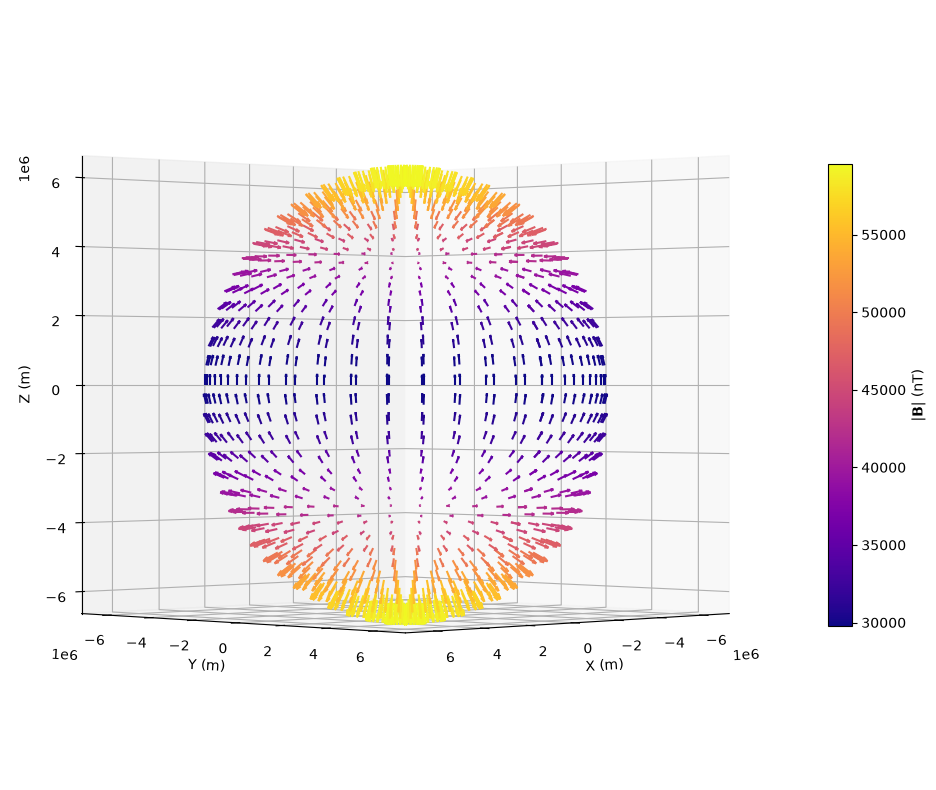

In [3]:
# # ! <Matplotlib> 3D vector plot
mag_B = np.sqrt(obs_bx**2 + obs_by**2 + obs_bz**2)
norm = plt.Normalize(vmin=mag_B.min(), vmax=mag_B.max())
cmap = cm.plasma  # Pick any colormap (e.g., viridis, plasma, coolwarm)
arrow_colors = cmap(norm(mag_B))
q_colors = np.concatenate([arrow_colors, arrow_colors, arrow_colors])

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
quiver = ax.quiver(obs_x, obs_y, obs_z, obs_bx, obs_by, obs_bz, 
                   length=10, colors=q_colors)
mappable = cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(mappable, ax=ax, label=r'$\vert\mathbf{B}\vert$ (nT)', 
             shrink=0.6)

ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_zlabel('Z (m)')
ax.set_box_aspect([1, 1, 1])
ax.view_init(elev=0, azim=45)

plt.tight_layout()
plt.show()

In [4]:
# # ! <Pyvista> 3D vector plot
mesh_obs = pv.PolyData(obs_xyz)
obs_B = np.column_stack((obs_bx, obs_by, obs_bz))
mesh_obs.point_data['vectors'] = obs_B
mesh_obs.point_data['magnitude'] = mag_B

custom_arrow = pv.Arrow(
    tip_length=0.25,      # Length of the cone tip (fraction of total)
    tip_radius=0.08,      # Thickness of the cone tip
    shaft_radius=0.02,    # Thickness of the cylinder shaft
    tip_resolution=24,    # Smoothness of the tip
    shaft_resolution=24   # Smoothness of the shaft
)

arrows = mesh_obs.glyph(
    orient='vectors',
    scale='magnitude',
    factor=10,         
    geom=custom_arrow,
    progress_bar=False
)

pl = pv.Plotter(notebook=True, window_size=[800, 600], image_scale=3)
pl.set_background('white') 

pl.add_mesh(
    arrows,
    scalars='magnitude',
    cmap='plasma',        # 'plasma', 'viridis', or 'turbo' work great
    show_scalar_bar=True,
    scalar_bar_args={'title': r'$\vert\mathbf{B}\vert$ (nT)',
                     'color': 'black',
                     'fmt': '%.0f'}
)
pl.view_vector([1, 1, 0])
######## * Choose for static png
# pl.add_axes(color='black', label_size=(0.01, 0.01))
# pl.show(jupyter_backend='static')
######## * Choose for interactive 
pl.add_axes(color='black')
pl.show(jupyter_backend='client')

Widget(value='<iframe src="http://localhost:46553/index.html?ui=P_0x75714a080c90_0&reconnect=auto" class="pyvi…